# 04 – Part 2: results in pictures

Plots of the Part 2 **test** results. This notebook trains nothing: it only reads the CSVs that
`python -m src.part2_analysis --data-dir data/ml-1m` wrote to `results/part2_analysis/`, so it runs in seconds.
Re-run that script first if the models or the config change.

Every model has one fixed colour in all plots. The figures are also saved as PNG to
`results/part2_analysis/figures/` for the report.

| Section | Question |
|---|---|
| 1. Overall | How accurate is each model, and how much of the catalogue does it use? |
| 2. Paired tests | Which differences are real and which are noise? |
| 3. Seeds | How much does a stochastic model change with its random seed? |
| 4. Disaggregated | Who and what does each model work for (user activity, item popularity)? |
| 5. Sparsity | What happens with 50% and 20% of the training data? |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

# Works whether the notebook is started from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results" / "part2_analysis"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True)

# Fixed model order and one colour per model, the same as in 03_part2.ipynb
ORDER = ["MostPopular", "ItemKNN", "UserKNN", "ImplicitALS", "ImplicitBPR", "TwoTower"]
COLORS = {"MostPopular": "#2a78d6", "ItemKNN": "#eb6834", "UserKNN": "#1baf7a",
          "ImplicitALS": "#eda100", "ImplicitBPR": "#e87ba4", "TwoTower": "#008300"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e5e5e5", "grid.linewidth": 0.6, "lines.linewidth": 2,
                     "axes.axisbelow": True})


def save(fig, name):
    """Saves a figure for the report."""
    fig.savefig(FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")


overall = pd.read_csv(RESULTS / "part2_overall.csv").set_index("model")
pairs = pd.read_csv(RESULTS / "part2_paired_tests.csv")
subgroups = pd.read_csv(RESULTS / "part2_subgroups.csv")
runs = pd.read_csv(RESULTS / "part2_runs.csv")
sparsity = pd.read_csv(RESULTS / "part2_sparsity.csv")
random_ndcg = pd.read_csv(ROOT / "results" / "reference_bounds.csv").set_index("Model").loc["Random", "NDCG@10"]
print(f"{len(overall)} models, {int(overall['users_evaluated'].iloc[0])} test users, {len(runs)} training runs")

6 models, 1188 test users, 54 training runs


## 1. Overall test results

Left: NDCG@10 with a 95% confidence interval over test users, i.e. how much the number would move with a
different set of test users. Right: catalogue coverage, the share of all movies that appear in at least one
top-10 list. Both are for the tuned configuration with seed 42, trained on train + validation.

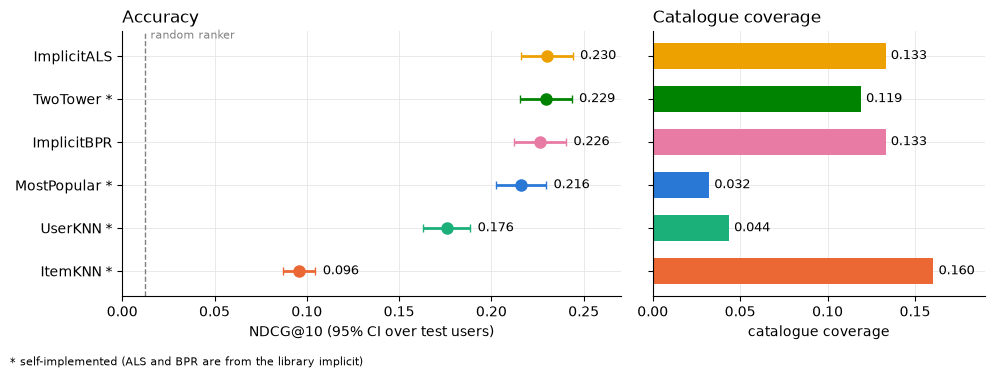

In [2]:
o = overall.loc[ORDER].sort_values("ndcg_at_10")  # best model on top
y = np.arange(len(o))
labels = [f"{name}{' *' if row.self_implemented else ''}" for name, row in o.iterrows()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, gridspec_kw={"width_ratios": [3, 2]})
for i, (name, row) in enumerate(o.iterrows()):
    err = [[row.ndcg_at_10 - row.ndcg_ci95_low_users], [row.ndcg_ci95_high_users - row.ndcg_at_10]]
    ax1.errorbar(row.ndcg_at_10, i, xerr=err, fmt="o", color=COLORS[name], markersize=8, capsize=3)
    ax1.text(row.ndcg_ci95_high_users + 0.004, i, f"{row.ndcg_at_10:.3f}", va="center", fontsize=9)
    ax2.barh(i, row.catalogue_coverage, color=COLORS[name], height=0.6)
    ax2.text(row.catalogue_coverage + 0.003, i, f"{row.catalogue_coverage:.3f}", va="center", fontsize=9)
ax1.axvline(random_ndcg, color="grey", linestyle="--", linewidth=1)
ax1.text(random_ndcg + 0.003, len(o) - 0.6, "random ranker", color="grey", fontsize=8)
ax1.set_yticks(y, labels)
ax1.set_xlim(0, 0.27)
ax1.set_xlabel("NDCG@10 (95% CI over test users)")
ax2.set_xlabel("catalogue coverage")
ax2.set_xlim(0, 0.19)
ax1.set_title("Accuracy", loc="left")
ax2.set_title("Catalogue coverage", loc="left")
fig.text(0.01, -0.03, "* self-implemented (ALS and BPR are from the library implicit)", fontsize=8)
plt.tight_layout()
save(fig, "overall")
plt.show()

**What it shows**
- ALS, TwoTower and BPR are the best three, but **their intervals overlap almost completely**, and also
  overlap with MostPopular. Section 2 tests whether any of these gaps is real.
- UserKNN and especially ItemKNN are clearly worse; their intervals do not overlap with the top group.
- Accuracy and coverage tell different stories: MostPopular recommends almost the same 10 movies to
  everyone (3% of the catalogue) and is still close to the best models. ItemKNN uses the most of the
  catalogue but is the least accurate.

## 2. Paired tests: which differences are real?

For every pair of models, the per-user difference in NDCG@10 is tested with a paired t-test (both models are
scored on the same 1,188 users). With 15 pairs, the p-values are Holm-corrected: otherwise about one pair in
20 would look "significant" by luck alone.

Left: mean difference *row minus column*. Blue = the row model is better, red = worse; **bold with \*** =
significant after the Holm correction. Right: every model against MostPopular with the (unadjusted) 95% CI of
the difference; a filled marker means significant after correction.

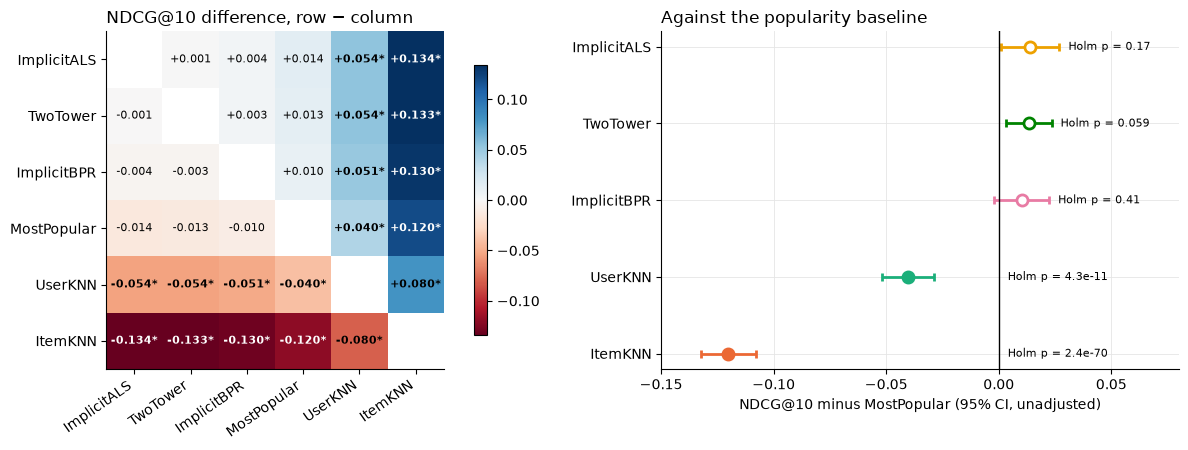

In [3]:
# Model order by overall NDCG, best first
by_ndcg = overall.loc[ORDER].sort_values("ndcg_at_10", ascending=False).index.tolist()
diff = pd.DataFrame(np.nan, index=by_ndcg, columns=by_ndcg)
significant = pd.DataFrame(False, index=by_ndcg, columns=by_ndcg)
for _, p in pairs.iterrows():
    diff.loc[p.model_a, p.model_b] = p.mean_difference_a_minus_b
    diff.loc[p.model_b, p.model_a] = -p.mean_difference_a_minus_b
    significant.loc[p.model_a, p.model_b] = significant.loc[p.model_b, p.model_a] = p.significant_at_0_05_holm

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
limit = np.nanmax(np.abs(diff.values))
image = ax1.imshow(diff.values, cmap="RdBu", norm=TwoSlopeNorm(vcenter=0, vmin=-limit, vmax=limit))
for i, a in enumerate(by_ndcg):
    for j, b in enumerate(by_ndcg):
        if i == j:
            continue
        star = significant.loc[a, b]
        ax1.text(j, i, f"{diff.loc[a, b]:+.3f}{'*' if star else ''}", ha="center", va="center", fontsize=8,
                 fontweight="bold" if star else "normal",
                 color="white" if abs(diff.loc[a, b]) > 0.6 * limit else "black")
ax1.set_xticks(range(len(by_ndcg)), by_ndcg, rotation=35, ha="right")
ax1.set_yticks(range(len(by_ndcg)), by_ndcg)
ax1.grid(False)
ax1.set_title("NDCG@10 difference, row − column", loc="left")
fig.colorbar(image, ax=ax1, shrink=0.8)

# Every model against MostPopular
vs = []
for name in by_ndcg:
    if name == "MostPopular":
        continue
    p = pairs[((pairs.model_a == name) & (pairs.model_b == "MostPopular")) |
              ((pairs.model_b == name) & (pairs.model_a == "MostPopular"))].iloc[0]
    sign = 1 if p.model_a == name else -1  # we want "model minus MostPopular"
    low, high = sorted([sign * p.difference_ci95_low, sign * p.difference_ci95_high])
    vs.append((name, sign * p.mean_difference_a_minus_b, low, high, p.p_value_holm, p.significant_at_0_05_holm))
for i, (name, d, low, high, p_holm, sig) in enumerate(reversed(vs)):
    ax2.errorbar(d, i, xerr=[[d - low], [high - d]], fmt="o", markersize=8, capsize=3, color=COLORS[name],
                 markerfacecolor=COLORS[name] if sig else "white", markeredgewidth=2)
    ax2.text(max(high, 0) + 0.004, i, f"Holm p = {p_holm:.2g}", va="center", fontsize=8)
ax2.axvline(0, color="black", linewidth=1)
ax2.set_yticks(range(len(vs)), [v[0] for v in reversed(vs)])
ax2.set_xlim(-0.15, 0.08)
ax2.set_xlabel("NDCG@10 minus MostPopular (95% CI, unadjusted)")
ax2.set_title("Against the popularity baseline", loc="left")
plt.tight_layout()
save(fig, "paired_tests")
plt.show()

**What it shows**
- **ALS, BPR and TwoTower cannot be told apart** (differences ≤ 0.004, Holm p = 1).
- **None of them is significantly better than MostPopular.** The gains are about +0.01 NDCG@10. Their unadjusted
  intervals barely exclude zero (ALS, TwoTower) or include it (BPR), and after correcting for 15 comparisons
  none survives (TwoTower comes closest, p ≈ 0.06).
- Everything significantly beats UserKNN and ItemKNN.
- Why the hollow markers can have intervals that do not cross zero: the interval is not corrected for the 15
  comparisons, the Holm p-value is. The corrected test is the one we report.

## 3. Seed variability

ALS, BPR and TwoTower start from random weights, so they were retrained with 5 seeds (42–46). Each dot is
one seed; the bar is the mean with a 95% CI over the seeds. The other three models are deterministic, so only
MostPopular is shown, as the dashed line.

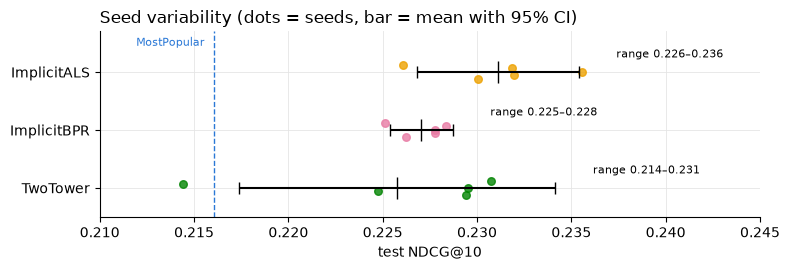

In [4]:
full = runs[runs.training_fraction == 1.0]
stochastic = ["ImplicitALS", "ImplicitBPR", "TwoTower"]
seed_order = full[full.model.isin(stochastic)].groupby("model").ndcg_at_10.mean().sort_values().index
summary = sparsity[sparsity.training_fraction == 1.0].set_index("model")

fig, ax = plt.subplots(figsize=(8, 2.8))
for i, name in enumerate(seed_order):
    values = full[full.model == name].ndcg_at_10.to_numpy()
    jitter = np.linspace(-0.12, 0.12, len(values))
    ax.scatter(values, i + jitter, color=COLORS[name], s=30, alpha=0.8, zorder=3)
    s = summary.loc[name]
    ax.errorbar(s.ndcg_at_10, i, xerr=[[s.ndcg_at_10 - s.ndcg_ci95_low], [s.ndcg_ci95_high - s.ndcg_at_10]],
                fmt="|", color="black", markersize=16, capsize=4, linewidth=1.5, zorder=4)
    ax.text(s.ndcg_ci95_high + 0.002, i + 0.25, f"range {values.min():.3f}–{values.max():.3f}", fontsize=8)
most_popular = full[full.model == "MostPopular"].ndcg_at_10.iloc[0]
ax.axvline(most_popular, color=COLORS["MostPopular"], linestyle="--", linewidth=1)
ax.text(most_popular - 0.0005, len(seed_order) - 0.55, "MostPopular", color=COLORS["MostPopular"],
        fontsize=8, ha="right")
ax.set_xlim(0.21, 0.245)
ax.set_ylim(-0.5, len(seed_order) - 0.3)
ax.set_yticks(range(len(seed_order)), seed_order)
ax.set_xlabel("test NDCG@10")
ax.set_title("Seed variability (dots = seeds, bar = mean with 95% CI)", loc="left")
plt.tight_layout()
save(fig, "seeds")
plt.show()

**What it shows**
- BPR barely moves with the seed (range ≈ 0.003); ALS a bit more.
- **TwoTower varies the most** (range ≈ 0.016, from 0.214 to 0.231), as the epoch-to-epoch swings in tuning
  suggested. Its worst seed is close to MostPopular, its best is the best single run of any model. A claim
  like "TwoTower beats ALS" would depend on the seed, which is one more reason not to make it.

## 4. Disaggregated results

**User activity**: users with no history ratings (Cold), and the others split at the median number of history
ratings (86): Low and High. **Item popularity**: only the user's relevant movies from one group count as hits:
the 20% most-rated movies, or the other 80% (the long tail). The long-tail panel has its own, much smaller scale.

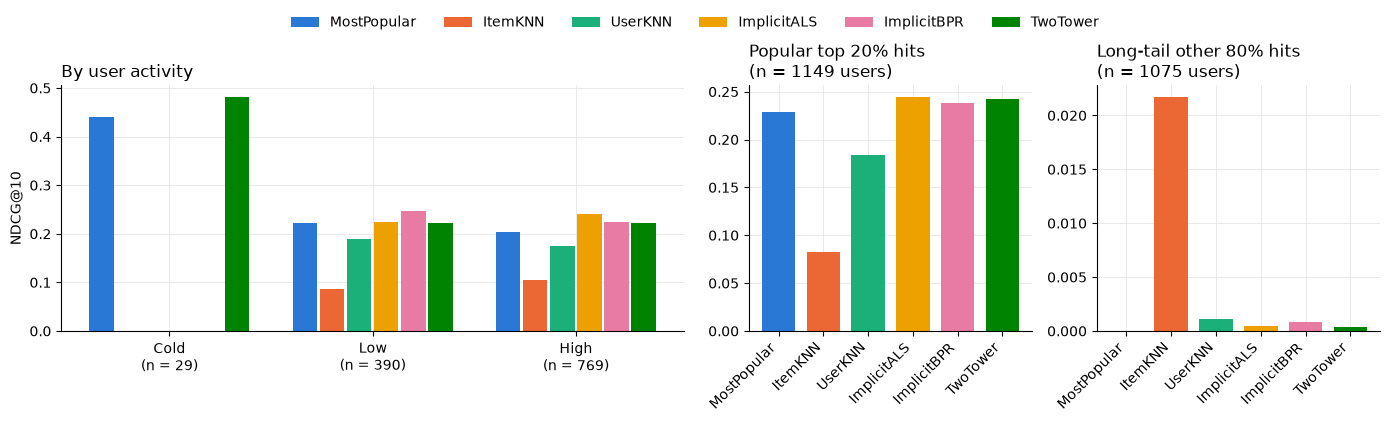

In [5]:
activity = subgroups[subgroups.dimension == "User activity"]
popularity = subgroups[subgroups.dimension == "Item popularity"]
segments = ["Cold", "Low", "High"]
n_users = activity.groupby("segment").users_evaluated.first()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1, 1]})
width = 0.8 / len(ORDER)
for j, name in enumerate(ORDER):
    values = activity[activity.model == name].set_index("segment").ndcg_at_10.reindex(segments)
    axes[0].bar(np.arange(3) + (j - 2.5) * width, values, width=width * 0.9, color=COLORS[name], label=name)
axes[0].set_xticks(range(3), [f"{s}\n(n = {n_users[s]})" for s in segments])
axes[0].set_ylabel("NDCG@10")
axes[0].set_title("By user activity", loc="left")

for ax, segment in zip(axes[1:], ["Popular top 20%", "Long-tail other 80%"]):
    part = popularity[popularity.segment == segment].set_index("model").loc[ORDER]
    ax.bar(range(len(ORDER)), part.ndcg_at_10, color=[COLORS[m] for m in ORDER], width=0.75)
    ax.set_xticks(range(len(ORDER)), ORDER, rotation=45, ha="right")
    n = int(part.users_evaluated.iloc[0])
    ax.set_title(f"{segment} hits\n(n = {n} users)", loc="left")
axes[2].yaxis.set_major_formatter(lambda v, _: f"{v:.3f}")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=6, frameon=False,
           bbox_to_anchor=(0.5, 1.06))
plt.tight_layout()
save(fig, "disaggregated")
plt.show()

**What it shows**
- **Cold users**: only TwoTower (from age, gender and occupation) and MostPopular can recommend anything; ALS,
  BPR and the kNN models return an empty list and score 0. Only 29 test users are cold, so these bars are
  noisy, but the zeros are structural.
- **Low vs High activity**: no consistent pattern. BPR is best on low-activity users, ALS on high-activity users,
  but the gaps (~0.02) are small for groups of 390 and 769 users.
- **Long tail**: every model is close to 0 (note the scale: ItemKNN's 0.02 is the best). Almost all hits of
  every model are popular movies, so the overall NDCG is really "how well does it rank popular movies".
  This is the motivation for a Part 3 diversity / popularity-bias track.

## 5. Sparsity ablation

Each model was trained on a random 50% or 20% of the train + validation ratings (3 different subsamples each)
with the same hyperparameters, and evaluated on the full test set. Movies the user rated in the dropped part
are still excluded from their recommendations. At 100%, the stochastic models are the mean over 5 seeds.

Left: NDCG@10 (bars = 95% CI over the repetitions). Middle: the same relative to each model's own 100% value,
i.e. how much of its accuracy it keeps. Right: catalogue coverage.

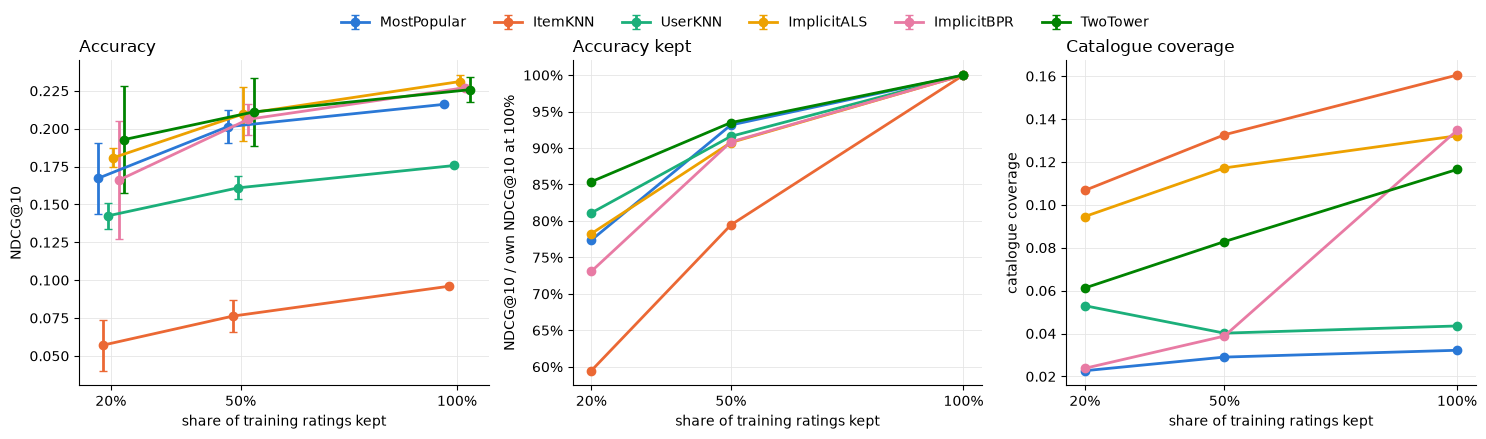

In [6]:
fractions = [0.2, 0.5, 1.0]
x = np.array([20, 50, 100])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for j, name in enumerate(ORDER):
    part = sparsity[sparsity.model == name].set_index("training_fraction").loc[fractions]
    low = (part.ndcg_at_10 - part.ndcg_ci95_low).fillna(0)
    high = (part.ndcg_ci95_high - part.ndcg_at_10).fillna(0)
    # small horizontal offset per model so the error bars do not hide each other
    axes[0].errorbar(x + (j - 2.5) * 1.2, part.ndcg_at_10, yerr=[low, high], color=COLORS[name], marker="o", markersize=6,
                     capsize=3, label=name)
    axes[1].plot(x, part.ndcg_at_10 / part.ndcg_at_10.loc[1.0], color=COLORS[name], marker="o", markersize=6)
    axes[2].plot(x, part.catalogue_coverage, color=COLORS[name], marker="o", markersize=6)
for ax in axes:
    ax.set_xticks(x, ["20%", "50%", "100%"])
    ax.set_xlabel("share of training ratings kept")
axes[0].set_ylabel("NDCG@10")
axes[0].set_title("Accuracy", loc="left")
axes[1].set_ylabel("NDCG@10 / own NDCG@10 at 100%")
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[1].set_title("Accuracy kept", loc="left")
axes[2].set_ylabel("catalogue coverage")
axes[2].set_title("Catalogue coverage", loc="left")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=6, frameon=False,
           bbox_to_anchor=(0.5, 1.05))
plt.tight_layout()
save(fig, "sparsity")
plt.show()

The ranking of the models in every single repetition (1 = best NDCG@10), to see whether the order at a given
sparsity is stable or depends on which subsample was drawn:

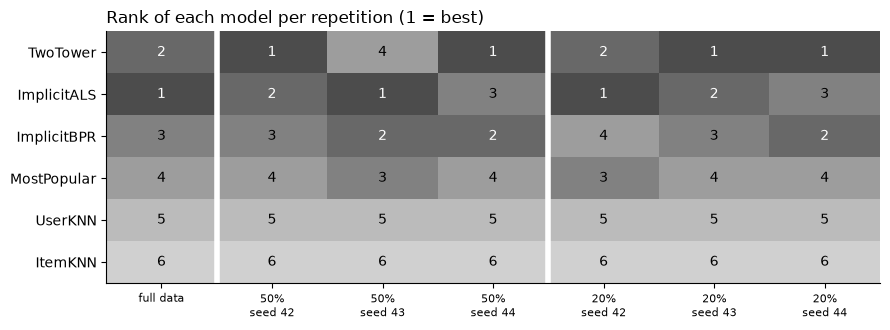

In [7]:
ranked = runs.dropna(subset=["repetition"])
columns = ["full data"] + [f"{f} sample, seed {s}" for f in ["50%", "20%"] for s in (42, 43, 44)]
ranks = ranked.pivot_table(index="model", columns="repetition", values="rank_in_repetition")[columns]
ranks = ranks.loc[ranks.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.imshow(ranks.values, cmap="Greys_r", vmin=-1.5, vmax=9, aspect="auto")
for i in range(ranks.shape[0]):
    for j in range(ranks.shape[1]):
        ax.text(j, i, int(ranks.iat[i, j]), ha="center", va="center", fontsize=10,
                color="white" if ranks.iat[i, j] <= 2 else "black")
ax.set_xticks(range(len(columns)), [c.replace(" sample, ", "\n") for c in columns], fontsize=8)
ax.set_yticks(range(len(ranks)), ranks.index)
for boundary in [0.5, 3.5]:
    ax.axvline(boundary, color="white", linewidth=4)
ax.grid(False)
ax.set_title("Rank of each model per repetition (1 = best)", loc="left")
plt.tight_layout()
save(fig, "sparsity_ranks")
plt.show()

**What it shows**
- **TwoTower degrades least**: it keeps about 85% of its accuracy at 20% of the data and ranks first in 5 of the
  6 sparse repetitions. Its features (genres, year, demographics) still carry signal when there are too few
  ratings to learn good ID embeddings; the pure collaborative models have nothing else to fall back on.
- **BPR collapses**: at 20% it keeps the smallest share of its accuracy among the top models and falls
  level with MostPopular (0.166 vs 0.167), while its coverage drops from 0.13 to 0.02, already to 0.04 at 50%. With little data it becomes a
  popularity recommender. ALS keeps its coverage much better.
- The top four still overlap within their intervals at each level (only 3 repetitions), so the robust finding is
  the trend (TwoTower up, BPR down), not the exact gaps. The bottom of the table never changes: UserKNN 5th,
  ItemKNN 6th in every repetition.
- Caveat: the hyperparameters were tuned on the full data and kept fixed, e.g. UserKNN's `min_support: 100` is an
  absolute count and filters out many more movies at 20%.

## Takeaways for the report

1. On the full data the three best models (ALS, BPR, TwoTower) are statistically tied, and **none is
   significantly better than MostPopular** after correcting for multiple comparisons.
2. The differences show up elsewhere: **TwoTower is the only learned model that handles cold users** and it is
   the **most robust under sparsity**; **BPR collapses towards popularity at 20%**.
3. Every model's hits are almost only popular movies (long-tail NDCG ≈ 0), and coverage is low, so the
   accuracy numbers mostly measure popularity ranking.